# Monitoring report

Does drift in incoming photos signal that the system is getting worse? Two experiments:

1. **Site replay** (`python -m retinaguard.monitoring.simulate`): every test site sent as daily batches of 250 photos, plus a gradual scenario in which a growing share of each EyePACS batch comes from DDR. Uses the deployed models' stored outputs.
2. **Degradation replay** (`python -m retinaguard.monitoring.replay`): all 516 IDRiD grading photos sent through the running API, clean and progressively blurred or darkened.

The reference is the EyePACS `calib` split. Charts and tables only; no images are shown.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from retinaguard.monitoring.replay import replay_summary

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
MONITORING = ROOT / "data" / "interim" / "monitoring"
reference = json.loads((ROOT / "outputs" / "models" / "reference.json").read_text())
batches = pd.read_csv(MONITORING / "site_batches.csv")
SITE_COLOURS = {"eyepacs_test": "#0072B2", "aptos": "#E69F00", "idrid": "#009E73", "ddr": "#CC79A7"}
SITE_NAMES = {
    "eyepacs_test": "EyePACS test (US)",
    "aptos": "APTOS (India)",
    "idrid": "IDRiD (India)",
    "ddr": "DDR (China)",
}
MUTED, GRID = "#5f5e5a", "#ebe9e2"


def style(ax):
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


print("reference rates:", {k: round(v, 3) for k, v in reference["rates"].items()})

reference rates: {'retake_rate': 0.138, 'defer_rate': 0.263, 'refer_rate': 0.153, 'ood_rate': 0.02}


## 1. Site replay

Each row is a batch of 250 photos. Drift signals: PSI of the referable probability, MMD between grader embeddings (with a permutation p-value) and the largest shift of an image statistic, in reference standard deviations. Performance, which a deployment only learns from reviewed cases: referable AUROC, the share of referable eyes cleared (FNR) and the calibration error (ECE).

In [2]:
columns = [
    "psi_p_referable",
    "mmd2",
    "max_image_shift",
    "retake_rate",
    "defer_rate",
    "ood_rate",
    "referable_share",
    "auroc",
    "fnr",
    "ece",
]
sites = batches[batches["scenario"] != "gradual"]
summary = sites.groupby("scenario", sort=False)[columns].mean()
summary["batches"] = sites.groupby("scenario", sort=False).size()
summary["MMD p < 0.01"] = sites.groupby("scenario", sort=False)["mmd_p"].apply(
    lambda p: (p < 0.01).mean()
)
summary["alerts"] = sites.groupby("scenario", sort=False)["alert"].apply(lambda a: a.notna().sum())
summary.rename(index=SITE_NAMES).round(3)

,psi_p_referable,mmd2,max_image_shift,retake_rate,defer_rate,ood_rate,referable_share,auroc,fnr,ece,batches,MMD p < 0.01,alerts
scenario,,,,,,,,,,,,,
EyePACS test (US),0.041,0.004,0.097,0.086,0.277,0.010,0.190,0.950,0.026,0.041,13,0.0,0
APTOS (India),0.790,0.140,0.903,0.117,0.173,0.005,0.391,0.972,0.000,0.105,14,1.0,0
IDRiD (India),1.366,0.272,0.355,0.086,0.166,0.016,0.624,0.988,0.000,0.040,2,1.0,0
DDR (China),0.352,0.063,0.404,0.202,0.177,0.041,0.454,0.973,0.021,0.061,49,1.0,32


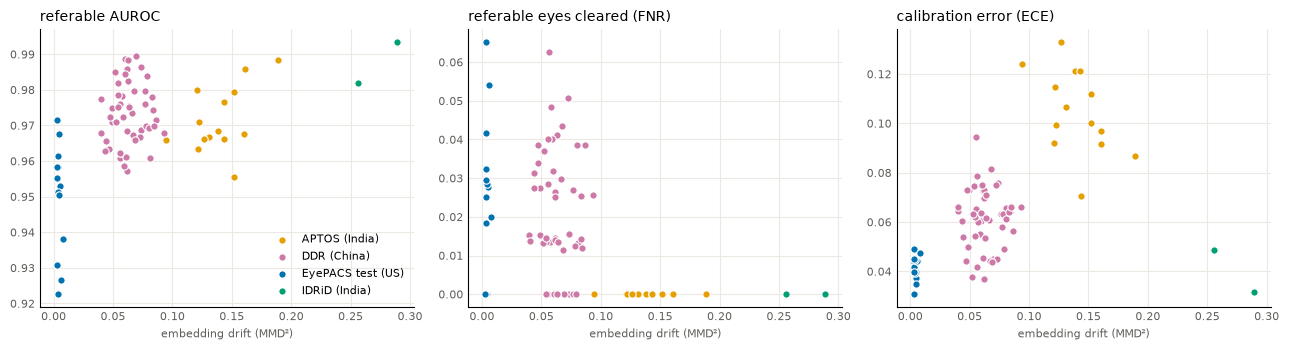

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for name, rows in sites.groupby("scenario"):
    for ax, metric in zip(axes, ["auroc", "fnr", "ece"], strict=True):
        ax.scatter(
            rows["mmd2"],
            rows[metric],
            s=28,
            color=SITE_COLOURS[name],
            label=SITE_NAMES[name],
            edgecolor="white",
            linewidth=0.8,
        )
for ax, label in zip(
    axes,
    ["referable AUROC", "referable eyes cleared (FNR)", "calibration error (ECE)"],
    strict=True,
):
    ax.set_xlabel("embedding drift (MMD²)", color=MUTED, fontsize=8)
    ax.set_title(label, fontsize=10, loc="left")
    style(ax)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Every batch from another site is detected (MMD p < 0.01) and no EyePACS batch is, but detection does not mean failure: AUROC is as high or higher on the external sites and the clearing error stays low. Much of the drift is case mix (far more referable eyes abroad), which moves the prediction distribution without harming discrimination. What does degrade is calibration, most on APTOS.

## 2. Gradual shift: EyePACS batches with a growing share of DDR photos

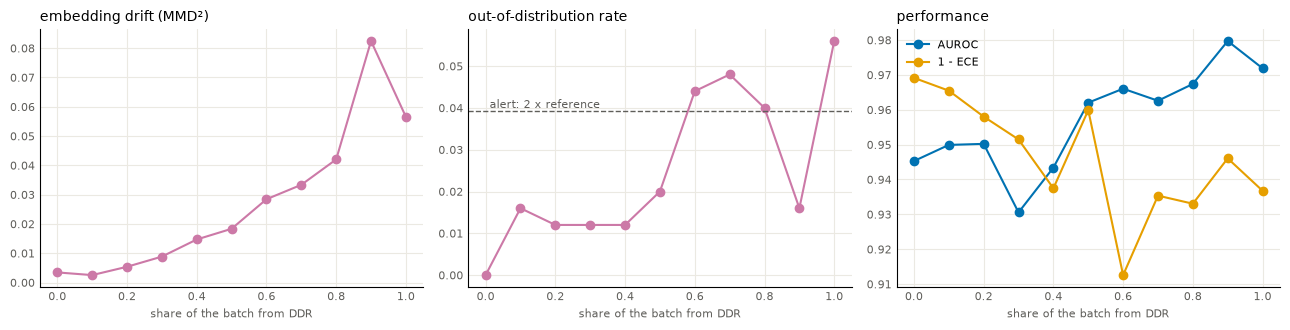

,ddr_share,mmd2,mmd_p,psi_p_referable,ood_rate,defer_rate,auroc,fnr,ece,alert
78,0.0,0.003,0.532,0.048,0.000,0.280,0.945,0.047,0.031,NaN
79,0.1,0.003,0.935,0.033,0.016,0.252,0.950,0.054,0.035,NaN
80,0.2,0.005,0.164,0.077,0.012,0.236,0.950,0.043,0.042,NaN
81,0.3,0.009,0.005,0.081,0.012,0.272,0.931,0.057,0.049,NaN
82,0.4,0.015,0.005,0.118,0.012,0.268,0.943,0.030,0.063,NaN
83,0.5,0.018,0.005,0.125,0.020,0.204,0.962,0.039,0.040,NaN
84,0.6,0.028,0.005,0.248,0.044,0.168,0.966,0.048,0.087,ood_rate 4.4% > 2 x reference 2.0%
85,0.7,0.033,0.005,0.224,0.048,0.208,0.963,0.045,0.065,ood_rate 4.8% > 2 x reference 2.0%
86,0.8,0.042,0.005,0.238,0.040,0.220,0.967,0.013,0.067,ood_rate 4.0% > 2 x reference 2.0%
87,0.9,0.082,0.005,0.425,0.016,0.168,0.980,0.000,0.054,NaN


In [4]:
gradual = batches[batches["scenario"] == "gradual"].copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(gradual["ddr_share"], gradual["mmd2"], marker="o", color="#CC79A7")
axes[0].set_title("embedding drift (MMD²)", fontsize=10, loc="left")
axes[1].plot(gradual["ddr_share"], gradual["ood_rate"], marker="o", color="#CC79A7")
axes[1].axhline(2 * reference["rates"]["ood_rate"], color=MUTED, linestyle="--", linewidth=1)
axes[1].text(
    0,
    2 * reference["rates"]["ood_rate"],
    " alert: 2 x reference",
    fontsize=8,
    color=MUTED,
    va="bottom",
)
axes[1].set_title("out-of-distribution rate", fontsize=10, loc="left")
axes[2].plot(gradual["ddr_share"], gradual["auroc"], marker="o", color="#0072B2", label="AUROC")
axes[2].plot(gradual["ddr_share"], 1 - gradual["ece"], marker="o", color="#E69F00", label="1 - ECE")
axes[2].set_title("performance", fontsize=10, loc="left")
axes[2].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xlabel("share of the batch from DDR", color=MUTED, fontsize=8)
    style(ax)
plt.tight_layout()
plt.show()
gradual[
    [
        "ddr_share",
        "mmd2",
        "mmd_p",
        "psi_p_referable",
        "ood_rate",
        "defer_rate",
        "auroc",
        "fnr",
        "ece",
        "alert",
    ]
].round(3)

## 3. Degradation replay through the API

The same 516 IDRiD photos, sent clean, blurred (Gaussian, σ in pixels of a 512 px image) and darkened. Here the photos really get worse, so the question is whether the signals move with the performance. The service stores no embeddings, so the OOD score stands in for embedding drift.

In [5]:
GRADES = ROOT / "data" / "raw" / "idrid" / "B. Disease Grading" / "2. Groundtruths"
LABELS = {
    "train": "a. IDRiD_Disease Grading_Training Labels.csv",
    "test": "b. IDRiD_Disease Grading_Testing Labels.csv",
}
ORDER = ["clean", "blur-1", "blur-2", "blur-4", "dark-0.5", "dark-0.3"]
frames = []
for path in sorted((MONITORING / "replay").glob("*.csv")):
    part = path.stem.rsplit("-", 1)[1]  # IDRiD reuses file names across its two sets
    labels = pd.read_csv(GRADES / LABELS[part]).dropna(subset=["Image name"])
    grade = labels.set_index("Image name")["Retinopathy grade"]
    table = pd.read_csv(path)
    frames.append(table.assign(dr_grade=table["file"].str.removesuffix(".jpg").map(grade)))
replayed = pd.concat(frames)
degradation = replay_summary(replayed, reference)
degradation["level"] = degradation["batch"].str.removeprefix("idrid-")
degradation = degradation.set_index("level").loc[
    [level for level in ORDER if level in set(degradation["level"])]
]
degradation.drop(columns="batch").round(3)

C:\Users\fidam\retinaguard\src\retinaguard\monitoring\replay.py:98: RuntimeWarning: Mean of empty slice
  "fnr": float(cleared[referable & graded].mean()),
C:\Users\fidam\retinaguard\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,photos,retake_rate,defer_rate,refer_rate,ood_rate,psi_p_referable,psi_ood_score,alert,auroc_graded,fnr,referable_retaken
level,,,,,,,,,,,
clean,516,0.116,0.149,0.523,0.004,1.082,0.022,,0.988,0.004,0.155
blur-1,516,0.176,0.188,0.488,0.002,1.103,0.227,,0.978,0.000,0.248
blur-2,516,0.826,0.064,0.035,0.000,0.208,3.448,retake_rate 82.6% > 2 x reference 13.8%,0.948,0.000,0.935
blur-4,516,1.000,0.000,0.000,NaN,NaN,NaN,retake_rate 100.0% > 2 x reference 13.8%,NaN,NaN,1.000
dark-0.5,516,0.273,0.132,0.393,0.003,0.808,0.064,,0.983,0.005,0.353
dark-0.3,516,0.816,0.023,0.054,0.011,0.309,0.578,retake_rate 81.6% > 2 x reference 13.8%,0.978,0.062,0.901


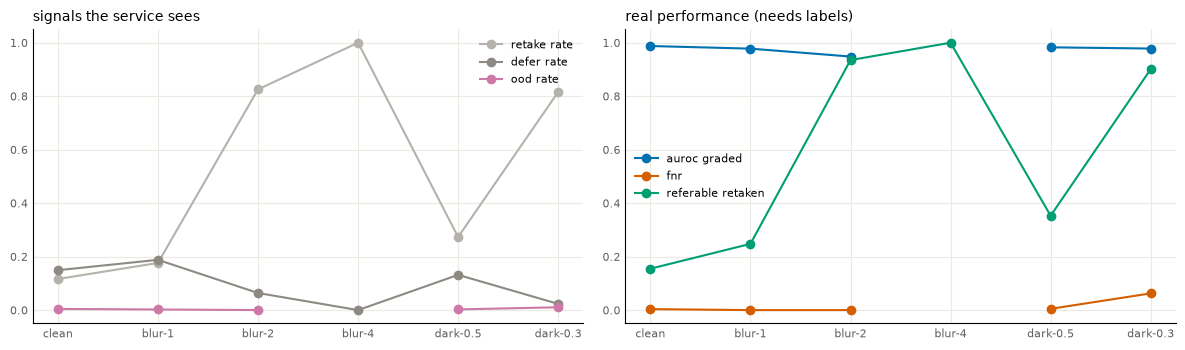

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = range(len(degradation))
for column, colour in [
    ("retake_rate", "#b4b2ab"),
    ("defer_rate", "#8c8a83"),
    ("ood_rate", "#CC79A7"),
]:
    axes[0].plot(x, degradation[column], marker="o", color=colour, label=column.replace("_", " "))
axes[0].set_title("signals the service sees", fontsize=10, loc="left")
for column, colour in [
    ("auroc_graded", "#0072B2"),
    ("fnr", "#D55E00"),
    ("referable_retaken", "#009E73"),
]:
    axes[1].plot(x, degradation[column], marker="o", color=colour, label=column.replace("_", " "))
axes[1].set_title("real performance (needs labels)", fontsize=10, loc="left")
for ax in axes:
    ax.set_xticks(list(x), degradation.index, fontsize=8)
    ax.legend(frameon=False, fontsize=8)
    style(ax)
plt.tight_layout()
plt.show()

## Conclusions

- **Drift is not failure here.** Embedding drift detects every batch from another site and never an EyePACS batch, but discrimination does not drop abroad; calibration does.
- **The quality gate is the first line of defence** against degraded photos: it sends back most blurred or darkened photos, so AUROC on what is graded stays high.
- **The alert rule must watch retakes.** Degraded photos become retakes and deferrals fall, so a rule on deferral and OOD rates alone never fired, even at 30% brightness, where graded photos missed 6.2% of referable eyes. The rule flags a batch whose retake, deferral or OOD rate exceeds twice the reference.
- **Only labels measure performance.** A random sample of each batch reviewed by a grader remains the way to know whether the system still works.